In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df = pd.read_csv("Healthcare Analytics for Doctor Visits.csv")
df.shape

(5190, 13)

In [3]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [4]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [6]:
df.isnull().sum()

,0
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


In [22]:
df.duplicated().sum()

np.int64(0)

In [8]:
print(df['gender'].value_counts())

gender
female    2702
male      2488
Name: count, dtype: int64


### 1. Univariate Analysis

Univariate analysis involves exploring individual variables one at a time to understand their distribution and central tendencies. We will examine the target variable `visits` and key numerical and categorical features like `income` and `gender`.

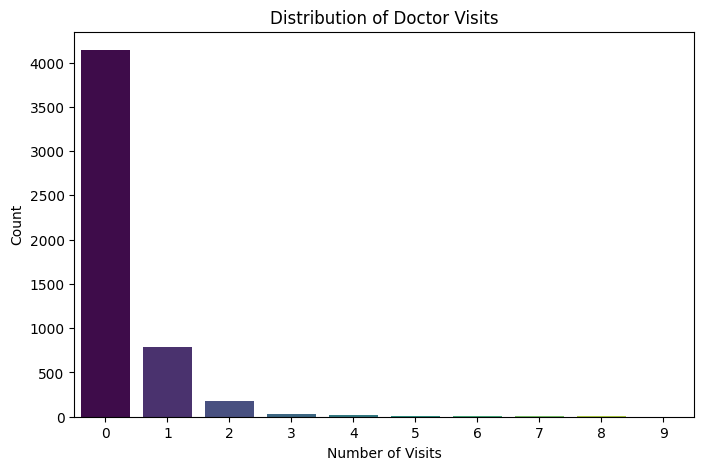

In [9]:
# Univariate plot for the target variable: Doctor Visits
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='visits', palette='viridis', hue='visits', legend=False)
plt.title('Distribution of Doctor Visits')
plt.xlabel('Number of Visits')
plt.ylabel('Count')
plt.show()

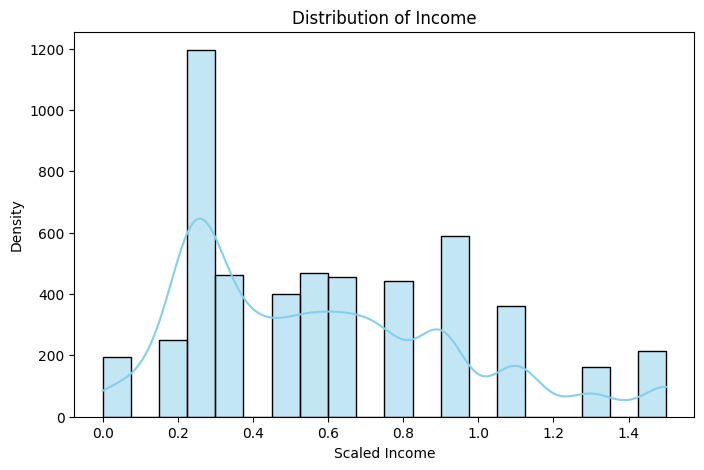

In [10]:
# Univariate plot for Income (Continuous variable)
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='income', kde=True, color='skyblue', bins=20)
plt.title('Distribution of Income')
plt.xlabel('Scaled Income')
plt.ylabel('Density')
plt.show()

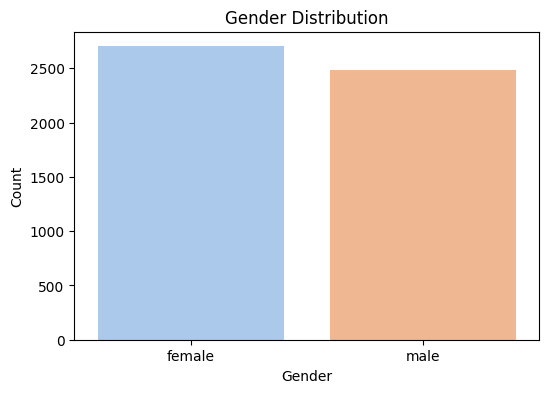

In [11]:
# Univariate plot for Gender (Categorical variable)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='gender', palette='pastel', hue='gender', legend=False)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### 2. Bivariate Analysis

Bivariate analysis explores the relationship between two variables. We will analyze:
- How doctor visits relate to gender.
- The relationship between income and private health insurance.
- How the number of illnesses relates to reduced activity days.

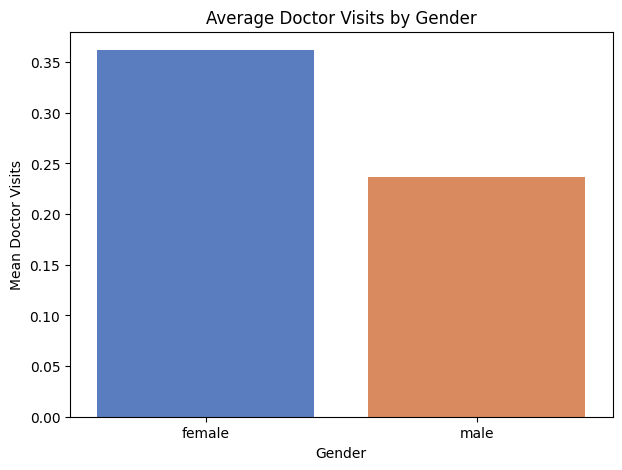

In [12]:
# Bivariate plot: Average Doctor Visits by Gender
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='gender', y='visits', palette='muted', errorbar=None, hue='gender', legend=False)
plt.title('Average Doctor Visits by Gender')
plt.xlabel('Gender')
plt.ylabel('Mean Doctor Visits')
plt.show()

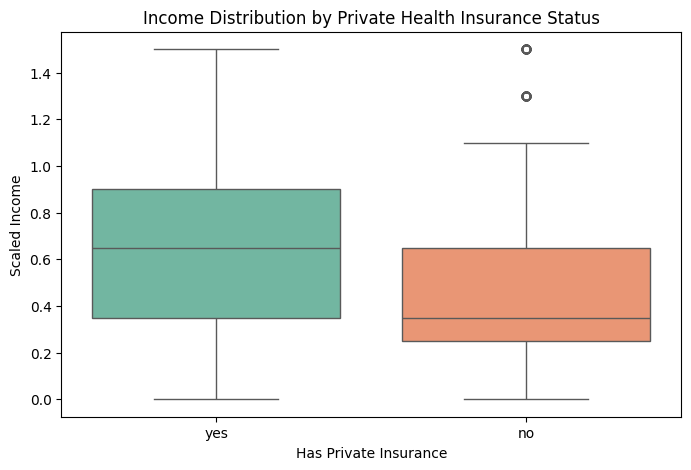

In [13]:
# Bivariate plot: Income Distribution by Private Insurance Status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='private', y='income', palette='Set2', hue='private', legend=False)
plt.title('Income Distribution by Private Health Insurance Status')
plt.xlabel('Has Private Insurance')
plt.ylabel('Scaled Income')
plt.show()

Private Health Insurance Counts:
private
no     2892
yes    2298
Name: count, dtype: int64


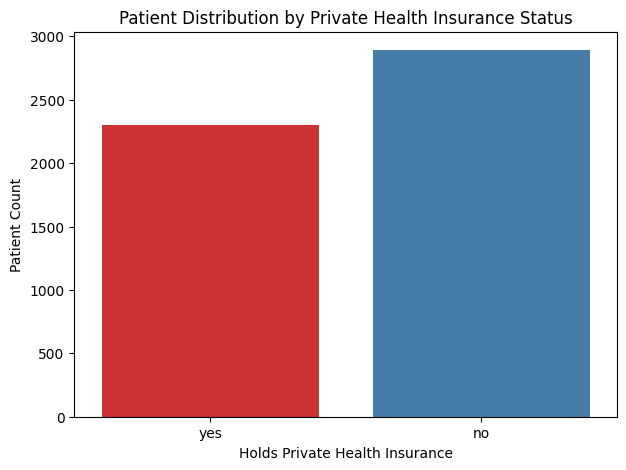

In [24]:
# Private Health Insurance Count Breakdown
print("Private Health Insurance Counts:")
print(df['private'].value_counts())

# Visualizing the distribution of private health insurance among the patients
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='private', palette='Set1', hue='private', legend=False)
plt.title('Patient Distribution by Private Health Insurance Status')
plt.xlabel('Holds Private Health Insurance')
plt.ylabel('Patient Count')
plt.show()

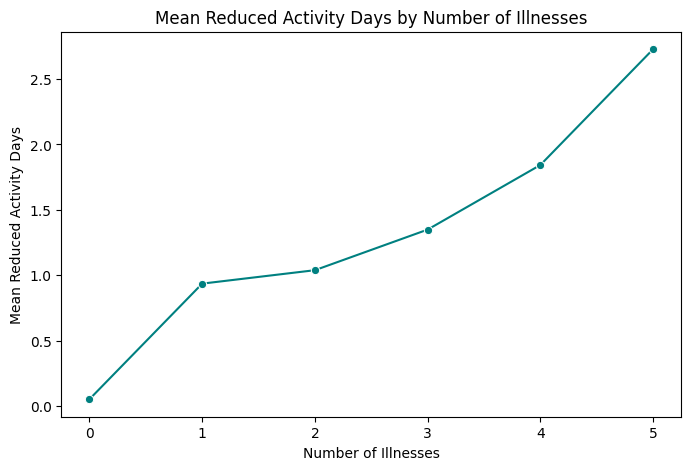

In [14]:
# Bivariate plot: Reduced Activity Days vs. Number of Illnesses
plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x='illness', y='reduced', color='teal', marker='o', errorbar=None)
plt.title('Mean Reduced Activity Days by Number of Illnesses')
plt.xlabel('Number of Illnesses')
plt.ylabel('Mean Reduced Activity Days')
plt.show()

### 3. Multivariate Analysis

Multivariate analysis helps us explore the interactions among three or more variables to understand complex patterns. We will construct:
- An lmplot showing doctor visits across age, separated by private health insurance ownership.
- A correlation heatmap of all numeric variables.

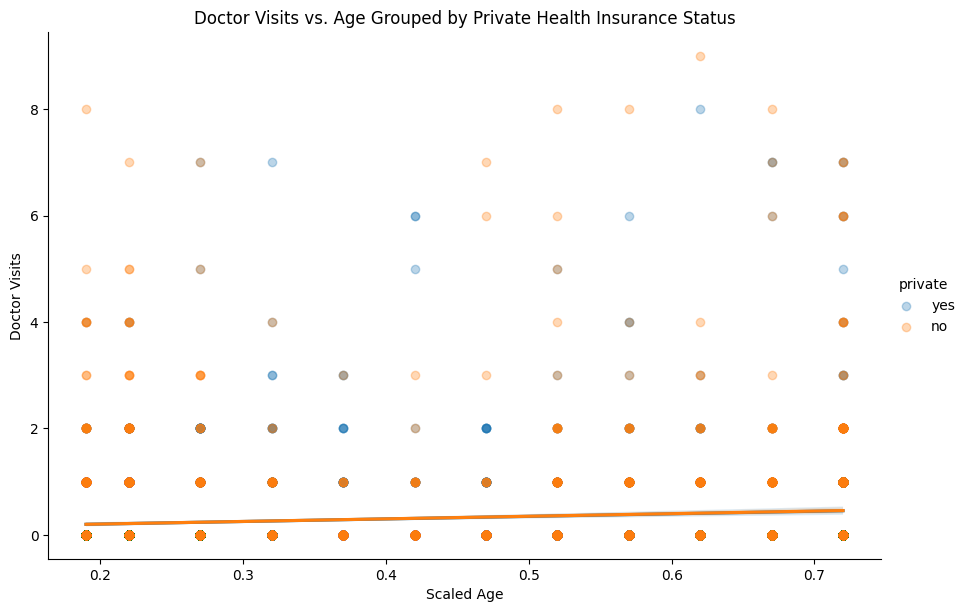

In [15]:
# Multivariate plot: Doctor Visits vs Age, categorized by Private Health Insurance
sns.lmplot(data=df, x='age', y='visits', hue='private', height=6, aspect=1.5, scatter_kws={'alpha':0.3})
plt.title('Doctor Visits vs. Age Grouped by Private Health Insurance Status')
plt.xlabel('Scaled Age')
plt.ylabel('Doctor Visits')
plt.show()

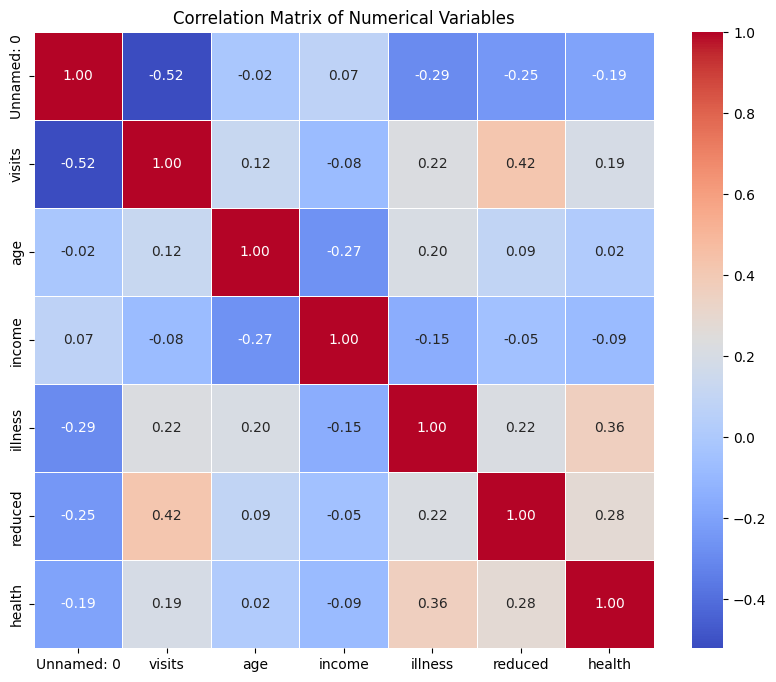

In [16]:
# Multivariate plot: Overall Correlation Heatmap of Numeric features
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

## 4. Machine Learning: Predicting Doctor Visits

In this section, we transition from exploration to prediction. We will construct a machine learning model to predict the number of `visits` utilizing the available health, demographic, and financial attributes.

### Workflow:
1. **Data Preprocessing**: Encode categorical variables into numeric format.
2. **Data Splitting**: Partition our dataset into training and testing sets.
3. **Model Selection**: Train a Random Forest Regressor.
4. **Evaluation**: Assess model performance using Mean Squared Error (MSE) and $R^2$ score.
5. **Feature Importance**: Identify which features contribute most to predicting doctor visits.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Drop the row index column 'Unnamed: 0'
ml_df = df.drop(columns=['Unnamed: 0'])

# Convert categorical object variables into dummy indicator variables
categorical_cols = ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
ml_df = pd.get_dummies(ml_df, columns=categorical_cols, drop_first=True)

# Define features (X) and target variable (y)
X = ml_df.drop(columns=['visits'])
y = ml_df['visits']

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (4152, 11)
Testing set shape: (1038, 11)


In [18]:
# Initialize and fit Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on test set
y_pred = rf_model.predict(X_test)

# Evaluate predictions
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Model Evaluation Metrics:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Model Evaluation Metrics:
Mean Squared Error (MSE): 0.7825
R-squared (R2): 0.1151


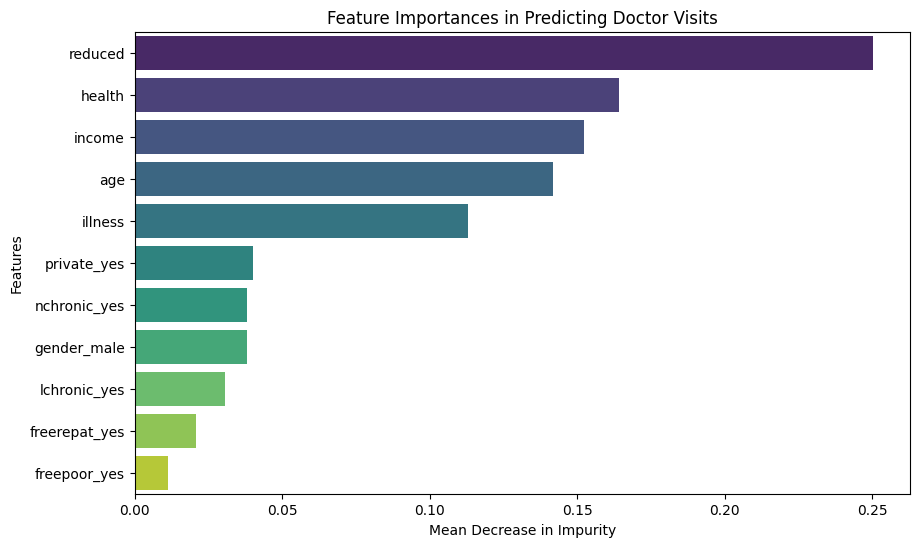

In [19]:
# Retrieve feature importances
importances = rf_model.feature_importances_
forest_importances = pd.Series(importances, index=X.columns).sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=forest_importances.values, y=forest_importances.index, palette='viridis', hue=forest_importances.index, legend=False)
plt.title('Feature Importances in Predicting Doctor Visits')
plt.xlabel('Mean Decrease in Impurity')
plt.ylabel('Features')
plt.show()

## 5. Conclusions & Project Summary

### Key Findings from Analysis:
1. **High Impact of Recent Activity & Health Limitations**:
   * Based on our machine learning feature importance analysis, **`reduced`** (days of reduced activity) and **`health`** (self-reported general health status score) are the strongest predictors of doctor visits.
   * This makes sense clinically: patients with severe health-limiting symptoms or chronic flare-ups require direct, immediate clinical intervention.

2. **Socio-Economic Factors (`income` & `private` insurance)**:
   * Bivariate and multivariate plots highlight that higher-income individuals are heavily clustered in the private health insurance category.
   * `income` and `age` represent the third and fourth most influential factors driving the prediction model.

3. **Demographic & Structural Drivers**:
   * Female patients exhibit a higher average frequency of doctor visits than male patients.
   * Although `gender` and administrative criteria such as `freepoor` or `freerepat` (free government assistance) are present, they are relatively minor contributors to predicting the total volume of visits compared to physical illness indications.

---

*This completes the Healthcare Analytics for Doctor Visits Data Analysis Project!*